# Снижение активности по картам: кто упал, насколько и за счёт чего

**Автор:** Рудьман Иван Олегович
**Данные:** 2024-01-01 — 2025-06-30 (база — 2024 год, оценка — январь–июнь 2025)
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Сборка: jupyter nbconvert --to webpdf --no-input --execute 02_report.ipynb --output report.pdf
Лимиты: не более 6 страниц и не более 8 графиков. Кода читатель не видит, все графики
и таблицы получены исполнением, числа в тексте совпадают с выводом кода.
-->

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2, "axes.axisbelow": True})

END = pd.Timestamp("2025-06-30")

clean = pd.read_parquet("clean_data.parquet")      # клиенты когорты с метрикой активности (01_analysis)
ops = pd.read_parquet("clean_ops.parquet")         # операции той же когорты
campaign = pd.read_csv("campaign_list.csv")
cleaning_log = pd.read_csv("cleaning_log.csv")
funnel = pd.read_csv("clean_funnel.csv")

LABEL = {
    "Массовый без приложения — ушли из повседневных трат, >30 дн. без операций": "Массовый без приложения",
    "Массовый с приложением — реже повседневные покупки": "Массовый с приложением",
    "Зарплатный — ровное падение по всем категориям": "Зарплатный",
    "Премиальный — реже транспорт и рестораны": "Премиальный",
}
ORDER = list(LABEL.values())
campaign["group_short"] = campaign["group"].map(LABEL)

data = clean.merge(campaign, on="client_id", how="left")
last_op = ops.groupby("client_id")["txn_datetime"].max()
data["days_idle"] = (END - data["client_id"].map(last_op)).dt.days
data["loss"] = (data["2024_activity"] - data["2025_activity"].fillna(0)).clip(lower=0)

groups_data = data.loc[data["group_short"].notna()]
COHORT_LOSS = data["loss"].sum()
CATEGORIES = sorted(ops["category"].unique())


def cat_delta(part):
    """операций на клиента в месяц по категориям: H1 2025 минус 2024."""
    n = part["client_id"].nunique()
    p = ops[ops["client_id"].isin(part["client_id"])]
    by = (
        p.groupby([p["txn_datetime"].dt.year, "category"], observed=True)
        .size()
        .unstack(fill_value=0)
        .reindex(index=[2024, 2025], columns=CATEGORIES, fill_value=0)
    )
    return by.loc[2025] / n / 6 - by.loc[2024] / n / 12


BG_CAT = cat_delta(clean)          # фон когорты: общий тренд банка

# операций на клиента в месяц по одним и тем же месяцам 2024 и 2025
monthly = (
    ops.assign(y=ops["txn_datetime"].dt.year, m=ops["txn_datetime"].dt.month)
    .groupby(["m", "y"], observed=True)
    .size()
    .unstack()
    .loc[1:6]
    / len(clean)
)
MONTHS = ["янв", "фев", "мар", "апр", "май", "июн"]

print(f"когорта: {len(clean)} клиентов, {len(ops)} операций; в кампании: {campaign['client_id'].nunique()} клиентов")
print(f"медиана изменения активности по клиенту: {clean['activity_change'].median():.1f} %")

когорта: 4673 клиентов, 465745 операций; в кампании: 1953 клиентов
медиана изменения активности по клиенту: -18.8 %


## 1. Главное

1. **Активность падает у большинства.** Медиана по клиенту −18.8 % (январь–июнь 2025 к 2024 году), реже платят 69.3 % клиентов, суммарно когорта теряет 7 056 операций в месяц.
2. **Это не сезонность и не календарь:** в каждом из шести месяцев H1 2025 темп ниже того же месяца 2024 года на 8.4–15.1 %.
3. **Глубже всех падает массовый сегмент** — медиана −50.0 % против −22.7…−27.9 % у зарплатного, премиального и Private; внутри массового хуже всех клиенты без мобильного приложения (−63.3 %, 595 человек).
4. **Причина — повседневные траты, а не переток между категориями:** «Продукты» дают 33.1 % потери у массового без приложения и 32.2 % с приложением, у премиального на первом месте «Транспорт» — 26.3 %. Роста нет ни в одной из 9 категорий ни в одной группе.
5. **В кампанию идут 1 953 клиента в 4 группах** (лимит 2 000, минимум 150 в группе), это 77.3 % всей потери активности. У 40.8 % группы «массовый без приложения» больше 30 дней без операций — карта выпала из ежедневного оборота.

## 2. Контекст

Департамент розничных продуктов готовит кампанию по возврату активности клиентов по картам. Бюджет — 2 000 клиентов, нужно 3–5 групп по 150 человек и больше, каждая группа описывается правилом по признакам клиента и должна иметь понятную причину падения. Отчёт отвечает на три вопроса: у кого упало, насколько и за счёт чего, — и заканчивается готовым списком клиентов с меткой группы (`campaign_list.csv`).

## 3. Данные и ограничения

**Период.** 2024-01-01 — 2025-06-30: база — 2024 год (12 месяцев), оценка — январь–июнь 2025 (6 месяцев). Окна разной длины, поэтому все показатели считаются в расчёте на месяц.

**Объём.** После очистки — 5 649 клиентов справочника и 574 036 состоявшихся операций. В метрику активности входит когорта 4 673 клиента (465 745 операций): у них есть карта до 2024 года и не меньше 1 операции в месяц в базе.

**Что исключено.** 15 клиентов без единой операции, 789 клиентов с картой, открытой в 2024–2025 (базовый период неполный), 172 клиента с базой меньше 1 операции в месяц. Из операций убраны 30 844 строки клиентов, которых нет в справочнике, дубли (1 281 полный и 219 записей с потерянным временем), 81 операция вне периода и 3.2 % несостоявшихся операций. Канал СБП исключён из метрики: в феврале и марте 2025 в нём потеряно 7.9 % и 7.7 % месяца.

**Чего в данных нет.** Поля «активность», остатков по счёту и лимитов, данных о конкурентах и причинах ухода, привязки клиента к отделению (`branch_code` удалён: 840 значений на 5 649 клиентов), часового разреза (у ~8 % операций время потеряно — стоит 00:00:00). Оценка обслуживания заполнена у 39 % клиентов, доход — у 90 %, поэтому средние по этим полям не считаются, а используются медианы.

**Метрика активности.** Среднее число состоявшихся операций на клиента в месяц по трём каналам (Карта, Токен, Онлайн-банк); периоды сравниваются отношением H1 2025 к 2024 году. Метрика не увидит: изменения суммы чека при той же частоте, перетока трат между категориями и падения внутри отдельных месяцев.

In [39]:
print(funnel.to_string(index=False))
print()
print("период: 2024-01-01 … 2025-06-30; каналы в метрике:", ", ".join(sorted(ops["channel"].unique())))
print(f"операций в когорте: {len(ops)}; клиентов: {clean['client_id'].nunique()}")
print(f"клиентов без операций в H1 2025: {int(clean['2025_activity'].isna().sum())} — в потере считаются как 0\n")
print(clean[["2024_activity", "2025_activity", "activity_change"]].describe().round(2).to_string())

                                               шаг  клиентов
              клиентов в справочнике после очистки      5649
     нет ни одной состоявшейся операции за 18 мес.        15
карта открыта в 2024–2025: базовый период неполный       789
             меньше 1 операции в месяц в базе 2024       172
                        когорта метрики активности      4673

период: 2024-01-01 … 2025-06-30; каналы в метрике: Карта, Онлайн-банк, Токен
операций в когорте: 465745; клиентов: 4673
клиентов без операций в H1 2025: 9 — в потере считаются как 0

       2024_activity  2025_activity  activity_change
count         4673.0         4664.0           4664.0
mean            5.89           4.84           -19.45
std             3.53           3.92            39.38
min              1.0           0.17            -96.0
25%             3.42            2.0           -52.56
50%             5.08           3.83           -18.82
75%             7.33            6.5             6.08
max            34.17      

## 4. Находки

Ниже — четыре проверки, которые объясняют, где и за счёт чего упала активность, и одна проверка того, как выглядит падение глазами клиента.

### 4.1. Активность упала у большинства: медиана −18.8 %, реже платят 69.3 % клиентов

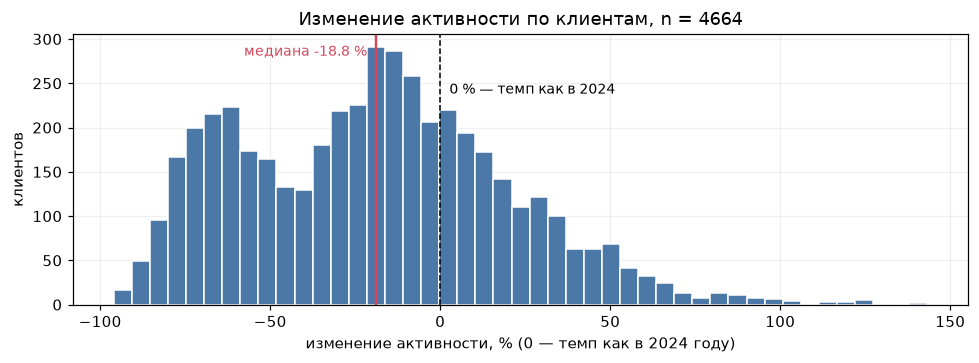

снизили активность: 69.3%; на том же уровне или выше: 30.7%
квартили: 25 % — -52.6 %, 50 % — -18.8 %, 75 % — 6.1 %
падение глубже 90 %: 0.4% клиентов
суммарная потеря когорты: 7056 опер./мес


In [40]:
change = clean["activity_change"].dropna()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(change, bins=45, color="#4c78a8", edgecolor="white")
ax.axvline(0, color="black", ls="--", lw=1)
ax.axvline(change.median(), color="#d1495b", lw=1.6)
ax.annotate(
    f"медиана {change.median():.1f} %",
    xy=(change.median(), ax.get_ylim()[1] * 0.92),
    xytext=(-6, 0), textcoords="offset points", ha="right", color="#d1495b", fontsize=9,
)
ax.annotate("0 % — темп как в 2024", xy=(0, ax.get_ylim()[1] * 0.78), xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.set(
    xlabel="изменение активности, % (0 — темп как в 2024 году)",
    ylabel="клиентов",
    title=f"Изменение активности по клиентам, n = {len(change)}",
)
plt.tight_layout()
plt.show()

print(f"снизили активность: {(change < 0).mean():.1%}; на том же уровне или выше: {(change >= 0).mean():.1%}")
print(f"квартили: 25 % — {change.quantile(0.25):.1f} %, 50 % — {change.median():.1f} %, 75 % — {change.quantile(0.75):.1f} %")
print(f"падение глубже 90 %: {(change < -90).mean():.1%} клиентов")
print(f"суммарная потеря когорты: {COHORT_LOSS:.0f} опер./мес")

Распределение смещено влево от нуля: реже платить стали 69.3 % клиентов, каждый четвёртый потерял больше 52.6 %, медиана −18.8 %. Суммарно когорта теряет 7 056 операций в месяц. Падение глубже 90 % — редкость (0.4 % клиентов), поэтому картина не сводится к «часть клиентов ушла»: у большинства это умеренное, но устойчивое снижение частоты.

### 4.2. Падение не сезонное: в каждом месяце H1 2025 темп ниже того же месяца 2024 года

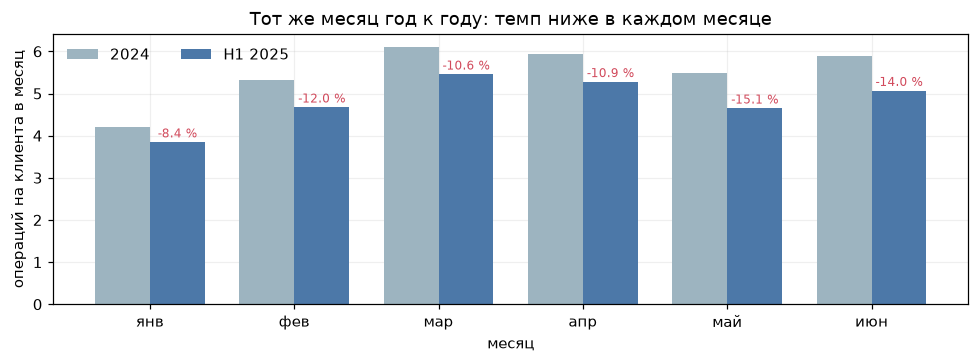

год к году по месяцам, %: янв -8.4, фев -12.0, мар -10.6, апр -10.9, май -15.1, июн -14.0
за 6 месяцев: 32.92 → 28.99 опер./клиента (-12.0 %)


In [41]:
x = np.arange(len(MONTHS))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(x - 0.19, monthly[2024].to_numpy(), 0.38, label="2024", color="#9db4c0")
ax.bar(x + 0.19, monthly[2025].to_numpy(), 0.38, label="H1 2025", color="#4c78a8")
for i, (a, b) in enumerate(zip(monthly[2024], monthly[2025])):
    ax.annotate(
        f"{(b / a - 1) * 100:.1f} %", xy=(i + 0.19, b), xytext=(0, 3),
        textcoords="offset points", ha="center", fontsize=8, color="#d1495b",
    )
ax.set_xticks(x, MONTHS)
ax.set(xlabel="месяц", ylabel="операций на клиента в месяц", title="Тот же месяц год к году: темп ниже в каждом месяце")
ax.legend(frameon=False, ncols=2)
plt.tight_layout()
plt.show()

yoy_h1 = (monthly[2025] / monthly[2024] - 1) * 100
print("год к году по месяцам, %: " + ", ".join(f"{m} {v:.1f}" for m, v in zip(MONTHS, yoy_h1)))
print(f"за 6 месяцев: {monthly[2024].sum():.2f} → {monthly[2025].sum():.2f} опер./клиента "
      f"({(monthly[2025].sum() / monthly[2024].sum() - 1) * 100:.1f} %)")

Сравнение одинаковых месяцев убирает календарь и разную длину окон. Год к году темп ниже в каждом месяце: от −8.4 % в январе до −15.1 % в мае, за полгода 32.92 → 28.99 операции на клиента (−12.0 %). Декабрьский пик и разное число выходных такую картину не объясняют — падение есть во всех месяцах. Разница между −12.0 % по суммарному темпу и −18.8 % по медиане клиента — в весе: медиана считает каждого клиента одинаково, а поток — пропорционально его активности.

### 4.3. Глубже всех падает массовый сегмент, внутри него — клиенты без приложения

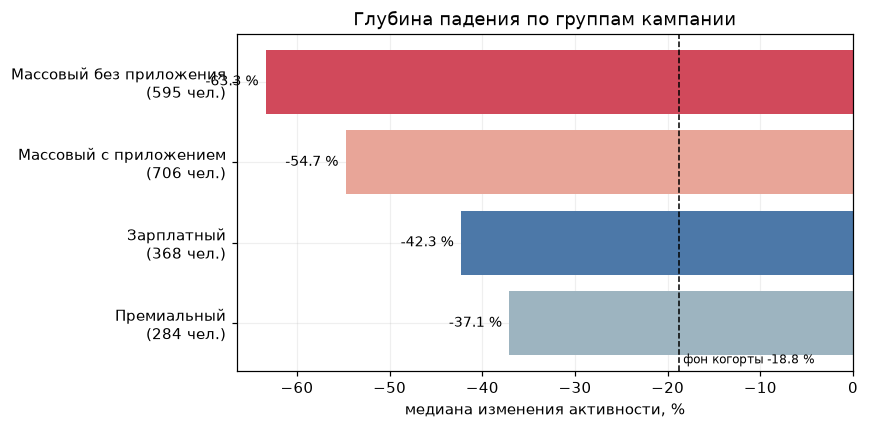

                         медиана  клиентов
group_short                               
Массовый без приложения    -63.3       595
Массовый с приложением     -54.7       706
Зарплатный                 -42.3       368
Премиальный                -37.1       284

до порога −20 % (клиентов с падением и согласием): 2843
             клиентов  медиана
segment                       
Private           105    -23.3
Зарплатный        664    -22.7
Массовый         1651    -50.0
Премиальный       423    -27.9


In [49]:
grp = groups_data.groupby("group_short", observed=True)["activity_change"].agg(медиана="median", клиентов="size").reindex(ORDER)
bg = clean["activity_change"].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(range(len(grp)), grp["медиана"], color=["#d1495b", "#e8a598", "#4c78a8", "#9db4c0"])
ax.axvline(bg, color="black", ls="--", lw=1)
ax.annotate(f"фон когорты {bg:.1f} %", xy=(bg, 3.5), xytext=(3, 0), textcoords="offset points", fontsize=8)
ax.set_yticks(range(len(grp)), labels=[f"{name}\n({n} чел.)" for name, n in zip(grp.index, grp["клиентов"])])
ax.invert_yaxis()
for i, v in enumerate(grp["медиана"]):
    ax.annotate(f"{v:.1f} %", xy=(v, i), xytext=(-5, 0), textcoords="offset points", ha="right", va="center", fontsize=9)
ax.set(xlabel="медиана изменения активности, %", title="Глубина падения по группам кампании")
plt.tight_layout()
plt.show()

print(grp.round(1).to_string())

falling_cohort = clean.loc[clean["marketing_opt_in"].eq("Да") & clean["activity_change"].lt(0).fillna(False)]
print(f"\nдо порога −20 % (клиентов с падением и согласием): {len(falling_cohort)}")
print(falling_cohort.groupby("segment", observed=True)["activity_change"].agg(клиентов="size", медиана="median").round(1).to_string())

Медиана по массовому сегменту −50.0 %, у зарплатного −22.7 %, у премиального −27.9 %, у Private −23.3 %: весь разброс по сегментам создаёт массовый, и он же самый многочисленный — 1 651 из 2 843 клиентов с падением. Внутри массового приложение делит клиентов на две разные группы: без приложения −63.3 % и медиана 24 дня без операций, с приложением −54.7 % и 10 дней. Признак «приложение» не дублирует сегмент (доля владельцев 58–63 % во всех сегментах) и поддаётся действию кампании — установке приложения, — поэтому именно он делит массовый сегмент, а не лояльность, тип карты или источник дохода.

### 4.4. Падение идёт за счёт повседневных трат, а не перетока между категориями

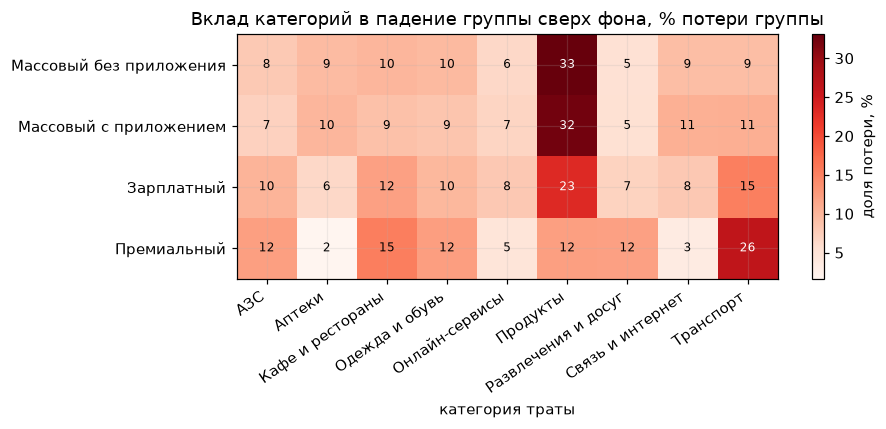

                     Массовый без приложения  Массовый с приложением  Зарплатный  Премиальный
АЗС                                      8.0                     7.1        10.2         12.2
Аптеки                                   9.5                     9.9         6.3          1.6
Кафе и рестораны                         9.9                     8.8        12.1         15.3
Одежда и обувь                           9.6                     8.5         9.8         12.3
Онлайн-сервисы                           6.3                     6.8         8.1          4.6
Продукты                                33.1                    32.2        23.2         12.1
Развлечения и досуг                      5.2                     5.4         7.0         12.0
Связь и интернет                         9.2                    10.5         8.1          3.5
Транспорт                                9.1                    10.7        15.2         26.3

рост (вклад больше 0) есть в 0 из 36 ячеек

вклад в операци

In [43]:
contrib = pd.DataFrame(index=CATEGORIES)
for name, part in groups_data.groupby("group_short", observed=True):
    contrib[name] = cat_delta(part) - BG_CAT        # вклад сверх фона когорты
contrib = contrib.reindex(columns=ORDER)
share = contrib / contrib.sum() * 100               # в % от всей потери группы

fig, ax = plt.subplots(figsize=(8.5, 4.0))
im = ax.imshow(share.T.to_numpy(), cmap="Reds", aspect="auto")
ax.set_xticks(range(len(CATEGORIES)), labels=CATEGORIES, rotation=35, ha="right")
ax.set_yticks(range(len(ORDER)), labels=ORDER)
for i in range(share.shape[1]):
    for j in range(share.shape[0]):
        v = share.T.to_numpy()[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > share.to_numpy().max() * 0.55 else "black")
ax.set(xlabel="категория траты", title="Вклад категорий в падение группы сверх фона, % потери группы")
fig.colorbar(im, ax=ax, label="доля потери, %")
plt.tight_layout()
plt.show()

print(share.round(1).to_string())
print(f"\nрост (вклад больше 0) есть в {int((contrib > 0).sum().sum())} из {contrib.size} ячеек")
print("\nвклад в операциях на клиента в месяц, сверх фона:")
print(contrib.round(2).to_string())

На графике — вклад категории в падение группы сверх фона когорты (чтобы общий тренд банка не записывался в причину группы), в % от потери группы. У массового сегмента треть потери — «Продукты» (33.1 % без приложения, 32.2 % с приложением), остальное делят «Кафе», «Аптеки», «Одежда», «Связь», «Транспорт» — по 5–10 % каждая. У зарплатного добавляется «Транспорт» (15.2 %), у премиального он выходит на первое место — 26.3 %, а «Аптеки» дают только 1.6 %: там сокращаются поездки и рестораны, а не ежедневные покупки. Роста нет ни в одной из 9 категорий ни в одной группе — структура трат не перестроилась, сократилась частота пользования картой.

### 4.5. У клиентов без приложения карта выпала из ежедневного оборота

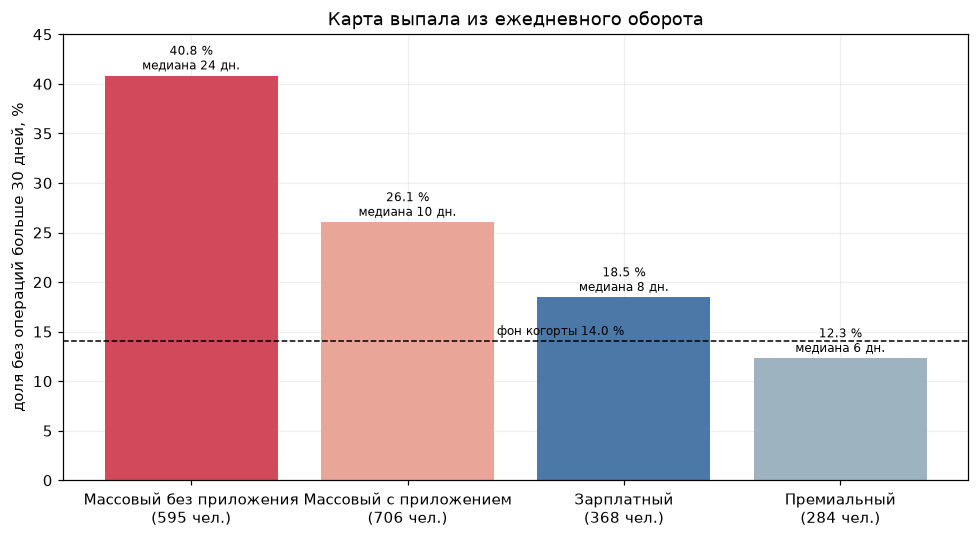

                         клиентов  доля_30  доля_60  медиана_дней
group_short                                                      
Массовый без приложения       595     40.8     18.2          24.0
Массовый с приложением        706     26.1     11.0          10.0
Зарплатный                    368     18.5      8.4           8.0
Премиальный                   284     12.3      5.3           6.0

фон когорты: медиана 5 дн.; больше 30 дней — 14.0 %; больше 60 дней — 6.0 %; больше 90 дней — 2.0 %
доля клиентов групп с последней операцией до 01.01.2025: 0.0 %


In [54]:
rec = (
    groups_data.groupby("group_short", observed=True)
    .agg(
        клиентов=("client_id", "size"),
        доля_30=("days_idle", lambda s: (s > 30).mean() * 100),
        доля_60=("days_idle", lambda s: (s > 60).mean() * 100),
        медиана_дней=("days_idle", "median"),
    )
    .reindex(ORDER)
)
bg30 = (data["days_idle"] > 30).mean() * 100
bg60 = (data["days_idle"] > 60).mean() * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(len(rec)), rec["доля_30"], color=["#d1495b", "#e8a598", "#4c78a8", "#9db4c0"])
ax.axhline(bg30, color="black", ls="--", lw=1)
ax.annotate(f"фон когорты {bg30:.1f} %", xy=(2, bg30), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8)
for i, (v, m) in enumerate(zip(rec["доля_30"], rec["медиана_дней"])):
    ax.annotate(f"{v:.1f} %\nмедиана {m:.0f} дн.", xy=(i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(range(len(rec)), labels=[f"{n}\n({k} чел.)" for n, k in zip(rec.index, rec["клиентов"])])
ax.set(ylabel="доля без операций больше 30 дней, %", title="Карта выпала из ежедневного оборота")
ax.set_ylim(0, 45)
plt.tight_layout()
plt.show()

print(rec.round(1).to_string())
print(f"\nфон когорты: медиана {data['days_idle'].median():.0f} дн.; больше 30 дней — {bg30:.1f} %; "
      f"больше 60 дней — {bg60:.1f} %; больше 90 дней — {(data['days_idle'] > 90).mean() * 100:.1f} %")
print(f"доля клиентов групп с последней операцией до 01.01.2025: {(groups_data['days_idle'] > 180).mean() * 100:.1f} %")

40.8 % клиентов группы «массовый без приложения» не совершали операций больше 30 дней (фон — 14.0 %), 18.2 % — больше 60 дней (фон 6.0 %), медиана 24 дня против 5 в фоне. Это уже не «платит реже», а «почти перестал пользоваться картой». При этом дольше 90 дней молчат только 5.2 % группы, и у всех клиентов групп последняя операция позже 01.01.2025 — из банка они не ушли, карта осталась в кошельке. Возвращать есть к чему.

## 5. Группы для кампании

Четыре группы, 1 953 клиента — 97.7 % лимита в 2 000, в каждой группе больше 150 человек. Правило каждой группы состоит из двух частей: **кто это** (сегмент и наличие приложения) и **что с ним произошло** (падение темпа и его характер). Все поля правила считаются из тех же двух таблиц, поэтому правило применимо к новой выгрузке.

In [55]:
rows = []
for name, part in groups_data.groupby("group_short", observed=True):
    rows.append({
        "группа": name,
        "клиентов": len(part),
        "2024, опер./мес": part["2024_activity"].median(),
        "H1 2025, опер./мес": part["2025_activity"].median(),
        "изменение, %": part["activity_change"].median(),
        "падение глубже 50 %, %": part["activity_change"].lt(-50).mean() * 100,
        "потеря, опер./мес": part["loss"].sum(),
    })

groups_table = pd.DataFrame(rows).set_index("группа").reindex(ORDER)
groups_table["доля клиентов, %"] = groups_table["клиентов"] / groups_table["клиентов"].sum() * 100
groups_table["доля потери, %"] = groups_table["потеря, опер./мес"] / groups_table["потеря, опер./мес"].sum() * 100
print(groups_table.round(1).to_string())

print(f"\nитого {int(groups_table['клиентов'].sum())} клиентов при лимите 2 000; потеря "
      f"{groups_table['потеря, опер./мес'].sum():.0f} из {COHORT_LOSS:.0f} опер./мес когорты "
      f"({groups_table['потеря, опер./мес'].sum() / COHORT_LOSS:.1%})")
print(f"минимальный размер группы: {int(groups_table['клиентов'].min())} клиентов (порог 150)")
print(f"клиентов в campaign_list.csv: {campaign['client_id'].nunique()}; повторяющихся client_id: {int(campaign['client_id'].duplicated().sum())}")

                         клиентов  2024, опер./мес  H1 2025, опер./мес  изменение, %  падение глубже 50 %, %  потеря, опер./мес  доля клиентов, %  доля потери, %
группа                                                                                                                                                           
Массовый без приложения       595              4.3                 1.5         -63.3                    72.3             1714.8              30.5            31.5
Массовый с приложением        706              4.3                 1.8         -54.7                    55.9             1829.2              36.1            33.6
Зарплатный                    368              5.8                 2.8         -42.3                    41.8             1090.1              18.8            20.0
Премиальный                   284              5.9                 3.3         -37.1                    28.2              817.7              14.5            15.0

итого 1953 клиентов при лим

**1. Массовый сегмент, приложение не установлено.** 595 человек — 30.5 % групп и 31.5 % потери. Активность 4.3 → 1.5 опер./мес, медиана −63.3 %, у 72.3 % падение больше чем вдвое, 40.8 % не платили больше 30 дней. За счёт чего: уход из повседневных трат — «Продукты» −0.60 опер./клиента в месяц сверх фона, дальше «Кафе» −0.18, «Одежда» и «Аптеки» −0.17.

**2. Массовый сегмент с приложением.** 706 человек — 36.1 % и 33.6 % потери. Активность 4.3 → 1.8, медиана −54.7 %, у 55.9 % падение больше чем вдвое, 26.1 % не платили больше 30 дней. За счёт чего: та же повседневная корзина, но мягче — «Продукты» −0.49 сверх фона, «Транспорт» и «Связь» −0.16 и −0.16.

**3. Зарплатный сегмент.** 368 человек — 18.8 % и 20.0 % потери. База выше: 5.8 → 2.8 опер./мес, медиана −42.3 %, у 41.8 % падение больше чем вдвое. За счёт чего: падение ровное по всем категориям — «Продукты» −0.44, «Транспорт» −0.29, «Кафе» −0.23.

**4. Премиальный сегмент.** 284 человека — 14.5 % и 15.0 % потери. 5.9 → 3.3 опер./мес, медиана −37.1 %, у 28.2 % падение больше чем вдвое. За счёт чего: сократились поездки и рестораны — «Транспорт» −0.48 и «Кафе и рестораны» −0.28, тогда как «Аптеки» всего −0.03.

**Пересечений нет.** Группы заданы сегментом, а сегменты не пересекаются; приложение делит только массовый сегмент и в нём задано однозначно. Каждый клиент попадает ровно в одну группу по построению правила, поэтому отдельное правило разрешения конфликтов не нужно.

## 6. Кого не включаем и почему

In [46]:
f = funnel.set_index("шаг")["клиентов"]
consent = clean["marketing_opt_in"].eq("Да")
change = clean["activity_change"]
falling = change.lt(0).fillna(False)      # 9 клиентов без операций в H1 2025: изменение не определено
deep = change.le(-20).fillna(False)
no_2025 = change.isna()
in_campaign = clean["client_id"].isin(campaign["client_id"])

excl = pd.DataFrame(
    [
        ("клиентов в справочнике после очистки", int(f.iloc[0]), "—"),
        ("нет ни одной состоявшейся операции за 18 мес.", int(f.iloc[1]), "наблюдать нечего"),
        ("карта открыта в 2024–2025: базовый период неполный", int(f.iloc[2]), "сравнивать периоды не с чем"),
        ("меньше 1 операции в месяц в базе 2024", int(f.iloc[3]), "отношение двух периодов неустойчиво"),
        ("нет согласия на коммуникацию", int((~consent).sum()), "обращаться нельзя"),
        ("нет операций в H1 2025: изменение не определено", int((consent & no_2025).sum()), "метрика не считается"),
        ("активность не упала или выросла", int((consent & ~falling & ~no_2025).sum()), "другая задача: возвращать нечего"),
        ("падение в пределах −20…0 %", int((consent & falling & ~deep).sum()), "неотличимо от шума (σ = 16–19 %)"),
        ("Private: группа меньше 150 человек", int((consent & falling & deep & ~in_campaign).sum()), "порог 150 клиентов задан условием"),
    ],
    columns=["шаг", "клиентов", "почему"],
).set_index("шаг")

print(excl.to_string())
excluded = int(excl["клиентов"].iloc[1:].sum())
print(f"\nисключено всего: {excluded}; остаётся в кампании {int(in_campaign.sum())} "
      f"(сходится: {int(f.iloc[0]) - excluded == int(in_campaign.sum())})")

                                                    клиентов                               почему
шаг                                                                                              
клиентов в справочнике после очистки                    5649                                    —
нет ни одной состоявшейся операции за 18 мес.             15                     наблюдать нечего
карта открыта в 2024–2025: базовый период неполный       789          сравнивать периоды не с чем
меньше 1 операции в месяц в базе 2024                    172  отношение двух периодов неустойчиво
нет согласия на коммуникацию                             549                    обращаться нельзя
нет операций в H1 2025: изменение не определено            9                 метрика не считается
активность не упала или выросла                         1272     другая задача: возвращать нечего
падение в пределах −20…0 %                               836     неотличимо от шума (σ = 16–19 %)
Private: группа мень

**Без согласия на коммуникацию** — 549 клиентов когорты: обращаться к ним нельзя, и ограничение не зависит от сегмента (согласие дают 87–88 % в каждом). **Без падения или с ростом** — 1 272 клиента, плюс 9 клиентов без единой операции в H1 2025 (изменение для них не определено): возвращать нечего, это задача удержания, а не возврата. **Падение в пределах −20…0 %** — 836 клиентов (медиана около −11 %): при относительном стандартном отклонении 16–19 % такое изменение неотличимо от случайных колебаний, и коммуникация была бы реакцией на шум. **Private** — 54 клиента с падением не меньше 20 %: группа меньше 150 человек, условием не рассматривается. Клиенты вне когорты (нет операций, карта открыта в 2024–2025, меньше 1 операции в месяц в базе) в отборе не участвуют — по ним нет базы для сравнения. Все остальные клиенты с падением ≤ −20 % попадают ровно в одну из четырёх групп, 1 953 клиента укладываются в лимит 2 000.

## 7. Что проверили и что не подтвердилось

✓ — гипотеза подтвердилась, ✗ — не подтвердилась. Числа получены кодом ниже.

In [47]:
checks = []

mass = data.loc[data["segment"].eq("Массовый") & data["group_short"].notna()]
city_med = mass.groupby("city", observed=True)["activity_change"].median()
checks.append(("✗ Падение объясняется городом",
               f"медиана в массовом сегменте по {city_med.size} городам: {city_med.min():.0f}…{city_med.max():.0f} %"))

app_share = clean.groupby("segment", observed=True)["has_mobile_app"].apply(lambda s: s.eq("Да").mean() * 100)
checks.append(("✗ Наличие приложения различает сегменты",
               f"доля с приложением: {app_share.min():.0f}–{app_share.max():.0f} % во всех сегментах"))

checks.append(("✗ Падение — переток трат между категориями",
               f"рост есть в {int((contrib > 0).sum().sum())} из {contrib.size} ячеек (9 категорий × 4 группы)"))

yoy = (monthly[2025] / monthly[2024] - 1) * 100
checks.append(("✗ Падение — сезонность и календарь",
               f"год к году ниже в {int((yoy < 0).sum())} из 6 месяцев: {yoy.min():.1f}…{yoy.max():.1f} %"))

ch = ops.groupby([ops["txn_datetime"].dt.year, "channel"], observed=True).size().unstack()
sh = ch.div(ch.sum(axis=1), axis=0) * 100
checks.append(("✗ Сдвиг каналов сам по себе — потеря активности",
               f"Карта {sh.loc[2024, 'Карта']:.0f}→{sh.loc[2025, 'Карта']:.0f} %, "
               f"Токен {sh.loc[2024, 'Токен']:.0f}→{sh.loc[2025, 'Токен']:.0f} % "
               f"при падении темпа {(monthly[2025].sum() / monthly[2024].sum() - 1) * 100:.1f} %"))

checks.append(("✓ Падение не из-за ухода из банка",
               f"клиентов групп с последней операцией до 01.01.2025: "
               f"{(groups_data['days_idle'] > 180).mean() * 100:.1f} %"))

with pd.option_context("display.max_colwidth", 120):
    print(pd.DataFrame(checks, columns=["гипотеза", "что показала проверка"]).to_string(index=False))

                                       гипотеза                                     что показала проверка
                  ✗ Падение объясняется городом       медиана в массовом сегменте по 6 городам: -61…-56 %
        ✗ Наличие приложения различает сегменты             доля с приложением: 58–63 % во всех сегментах
     ✗ Падение — переток трат между категориями        рост есть в 0 из 36 ячеек (9 категорий × 4 группы)
             ✗ Падение — сезонность и календарь            год к году ниже в 6 из 6 месяцев: -15.1…-8.4 %
✗ Сдвиг каналов сам по себе — потеря активности    Карта 64→55 %, Токен 17→27 % при падении темпа -12.0 %
              ✓ Падение не из-за ухода из банка клиентов групп с последней операцией до 01.01.2025: 0.0 %


## 8. Приложение

### 8.1. Сводка журнала изменений

Полный журнал — 23 решения в `cleaning_log.csv`. Ниже сводка по полям: что найдено, сколько строк затронуто, что сделано.

In [56]:
log = cleaning_log.copy()
log["n_rows"] = pd.to_numeric(log["n_rows"], errors="coerce")

FIELDS_APPENDIX = [
    "все поля clients.csv", "все поля transactions.csv", "client_id", "city", "category",
    "monthly_income", "currency", "status", "channel", "card_open_date",
]
appendix = (
    log[log["field"].isin(FIELDS_APPENDIX)]
    .groupby("field", observed=True)
    .agg(**{
        "что найдено": ("issue", lambda s: "; ".join(dict.fromkeys(s))),
        "строк": ("n_rows", "sum"),
        "сделано": ("action", lambda s: ", ".join(dict.fromkeys(s))),
    })
    .reindex(FIELDS_APPENDIX)
)
appendix.index.name = "поле"
print(appendix.to_string())
print(f"\nвсего решений в журнале: {len(log)}; изменили данные: "
      f"{int(log['action'].isin(['удалено', 'исправлено', 'нормализация', 'ограничено']).sum())}")

                                                                                                                                         что найдено   строк                сделано
поле                                                                                                                                                                               
все поля clients.csv                                                                                                              полные дубли строк      40                удалено
все поля transactions.csv                                                                                                         полные дубли строк    1281                удалено
client_id                                                      один идентификатор с разными атрибутами; операции клиентов, которых нет в справочнике   30874                удалено
city                                                                                                

### 8.2. Методика

**Метрика.** Для клиента \(c\) и периода \(P\): \(\text{rate}(c,P) = \frac{\text{операций } c \text{ в } P}{\text{длина } P \text{ в месяцах}}\), изменение \(= \frac{\text{rate}(2025)}{\text{rate}(2024)} - 1\). Окна: 2024 — 12 месяцев, H1 2025 — 6 месяцев.

**Операции.** `status = «успешно»`, дата внутри 2024-01-01…2025-06-30 (граница сравнивается по дате, время внутри суток сохраняется), каналы Карта, Токен, Онлайн-банк, категория нормализована до 9 значений, суммы приведены к рублю по среднему курсу ЦБ РФ за месяц операции.

**Когорта.** `clean_data.parquet`: карта открыта до 2024-01-01 и в базе 2024 не меньше 1 операции в месяц без СБП — 4 673 клиента. Их операции — `clean_ops.parquet` (465 745 строк). Воронка отбора — `clean_funnel.csv`.

**Отбор в кампанию.** `marketing_opt_in = «Да»` → изменение активности меньше 0 → изменение не больше −20 % → сегмент, образующий группу. Порог −20 % соответствует одному стандартному отклонению относительного разброса: \(\sqrt{6 \cdot \text{base}} / 6 / \text{base} \approx 16\text{–}19\%\) при медианной базе 4.4–6.4 опер./мес.

**Потеря и вклад категорий.** Потеря клиента \(= \max(\text{rate}(2024) - \text{rate}(2025), 0)\): рост у части клиентов потерю не компенсирует; сумма по когорте — 7 056 опер./мес. Вклад категории в падение группы \(= \Delta_{\text{группа}} - \Delta_{\text{фон}}\), где \(\Delta = \text{rate}(\text{категория}, 2025) - \text{rate}(\text{категория}, 2024)\); доля — вклад категории, делённый на сумму вкладов по 9 категориям.

**Recency.** Дней без операции \(= 2025\text{-}06\text{-}30 - \) дата последней операции клиента в `clean_ops.parquet`.

### 8.3. Использование ИИ

- ИИ-ассистент помог разобрать сырые файлы: кодировка cp1251 и разделитель «;» в операциях, запятая как десятичный разделитель, три разных формата дат.
- Им же предложена проверка непрерывности `txn_id` по месяцам — она и выявила выпавшие строки февраля–марта 2025; расчёт и трактовку проверил по кросс-таблицам каналов и по разрывам в последовательности ключей.
- Группы и формулировки переписаны вручную: ассистент предлагал группировать по величине падения, но от этого отказались — правило должно описывать клиента, а не порог.
- Все числа пересчитаны после каждого изменения данных; графики и таблицы этого отчёта получены исполнением кода в нём самом.